# Tokenization và text classification

Sau mỗi buổi học, lớp gửi vài dòng nhận xét: “ví dụ hay”, “bài giảng khó hiểu”, “không tệ”. Nếu có vài nghìn nhận xét, ta muốn tìm những phần cần sửa trước. Máy tính nhận được chuỗi ký tự, còn mô hình ở các chương trước nhận ma trận số. Câu hỏi đầu tiên vì thế chưa phải chọn mạng neural nào, mà là: **biến câu thành số thế nào để giữ được thông tin cần cho việc phân loại?** Bài này đi từ cách cắt văn bản đến một baseline chạy được, rồi đọc những câu mà baseline hiểu sai.

> **Mục tiêu sau bài này**
>
> - Phân biệt ký tự, âm tiết, từ và subword; kiểm tra tokenizer phù hợp với tiếng Việt.
> - Làm một bước học BPE và giải thích cách mã hóa WordPiece.
> - Dựng TF-IDF kết hợp logistic regression, so với Naive Bayes; chỉ học bộ biến đổi trên train.
> - Đọc confusion matrix và tìm lỗi do phủ định, từ lạ, dữ liệu trùng.

## Một khoảng trắng chưa chắc là một ranh giới từ

Trong C++, đọc bằng `cin >> s` lấy các mảnh ngăn bởi khoảng trắng. Ta có thể làm tương tự bằng `split()`, nhưng với câu “học sinh học máy”, kết quả `học`, `sinh`, `học`, `máy` là bốn âm tiết. Khi nói về người học và lĩnh vực AI, “học sinh” và “học máy” thường là hai đơn vị từ vựng. Tách từ tiếng Việt cần xét ngữ cảnh; không thể ghép mọi cặp âm tiết bằng một quy tắc cố định.

Token là đơn vị mà một hệ thống xử lý, không nhất thiết là từ trong ngôn ngữ học. Tokenizer có thể dùng từ, ký tự, byte hoặc subword (mảnh dưới từ). Cùng một câu sẽ có số token khác nhau dưới các tokenizer khác nhau. Ký hiệu $t_1,\ldots,t_L$ chỉ chuỗi token có độ dài $L$; mỗi token được tra thành một ID nguyên trong từ vựng $V$. ID là địa chỉ trong bảng, không phải mức độ hay dở: token ID 100 không “lớn nghĩa” hơn ID 20.



Ta chuẩn hóa Unicode về NFC trước khi đếm. Hai chuỗi trông giống hệt nhau có thể khác nhau ở mức mã: chữ “ọ” có thể là một ký tự dựng sẵn, hoặc chữ “o” theo sau là dấu nặng kết hợp `U+0323`. NFC gộp cách viết thứ hai về cách thứ nhất và vẫn giữ dấu; tự xóa dấu sẽ làm “ma”, “má”, “mà” mất khác biệt. Viết thường cũng là một lựa chọn theo nhiệm vụ: phù hợp với baseline nhận xét ở đây, nhưng có thể làm mất thông tin tên riêng trong NER ở bài 6.3.



In [ ]:
import unicodedata
import numpy as np

def normalize_text(text):
    text = unicodedata.normalize("NFC", text)
    return " ".join(text.lower().split())

sentence = "Học sinh học máy"
print(normalize_text(sentence).split())
nfc = unicodedata.normalize("NFC", "ho\u0323c")
print(nfc == "học")

['học', 'sinh', 'học', 'máy']
True


Dòng đầu là bốn âm tiết cắt theo khoảng trắng, chưa phải kết quả tách từ. Dòng thứ hai cho thấy chữ “o” cộng dấu nặng rời, sau NFC, trùng với “học” gõ sẵn. Với model pretrained, phải dùng đúng tokenizer và quy trình chuẩn hóa đi kèm model. Chẳng hạn, PhoBERT nhận văn bản đã tách từ, các âm tiết trong một từ nối bằng dấu gạch dưới (`học_sinh`); các model đa ngôn ngữ như mBERT hay XLM-R nhận văn bản thô và tự cắt subword.

**Hỏi nhanh.** `"học sinh".split()` trả về hai mảnh. Từ đó ta rút ra được điều gì?

- A. Trong tiếng Việt, giữa hai khoảng trắng luôn là đúng một từ
- B. Đây là hai âm tiết, còn theo ngữ cảnh có thể chúng là một từ
- C. Phải bỏ dấu trước, rồi mới ghép được thành một từ
- D. Model nào cũng cần nối các âm tiết bằng dấu `_`

<details><summary>Đáp án</summary>

B. Đây là hai âm tiết, còn theo ngữ cảnh có thể chúng là một từ

Khoảng trắng tiếng Việt ngăn các âm tiết, còn “học sinh” là một từ gồm hai âm tiết. Tách từ cần ngữ cảnh và đúng quy trình của tokenizer. Bỏ dấu không giải quyết được ranh giới từ, lại còn làm mất nghĩa. Nối bằng `_` là quy ước của PhoBERT sau bước tách từ, không phải yêu cầu chung của mọi model.

</details>

**Hỏi nhanh.** Chuỗi `b` in ra trông như “học”, nhưng `b == "học"` lại là `False`, và `[hex(ord(ch)) for ch in b]` cho `['0x68', '0x6f', '0x323', '0x63']`. Trước khi đếm token, nên xử lý thế nào?

- A. Dấu nặng đang tách rời khỏi chữ “o”, nên chuẩn hóa NFC
- B. Ký tự `0x323` là rác, nên xóa mọi ký tự không phải chữ cái
- C. Chuỗi bị lỗi mã hóa, nên bỏ dấu cả hai chuỗi rồi so
- D. Hai chuỗi khác chữ hoa thường, nên gọi `lower()` rồi so lại

<details><summary>Đáp án</summary>

A. Dấu nặng đang tách rời khỏi chữ “o”, nên chuẩn hóa NFC

`0x323` là dấu nặng kết hợp, đứng sau chữ “o”. Vì vậy `b` có 4 ký tự, còn “học” gõ sẵn chỉ có 3. NFC gộp “o” và dấu nặng thành “ọ”, nên hai chuỗi trùng nhau mà vẫn giữ dấu. Xóa `0x323` biến “học” thành “hoc”. Bỏ dấu cả hai chuỗi làm “ma”, “má”, “mà” trùng nhau. `lower()` không đụng tới cách ghép dấu.

</details>

## Subword: từ lạ được ghép từ những mảnh quen

Một từ vựng chứa mọi tên riêng, từ mới và lỗi gõ sẽ rất lớn. Chỉ dùng ký tự thì từ vựng nhỏ, nhưng chuỗi dài. Subword dung hòa hai điều: giữ các mảnh thường gặp thành token, chia những từ ít gặp thành nhiều mảnh. BPE (byte-pair encoding) bắt đầu từ các ký tự, đếm cặp token kề nhau trên train, gộp cặp có tần suất cao nhất thành một token mới, rồi lặp lại cho đến khi từ vựng đủ kích thước. Tần suất tính có trọng số theo số lần từ xuất hiện.

Để nhìn thuật toán mà không vướng dấu, dùng ba từ tiếng Anh do ta tự tạo corpus: `low` xuất hiện 3 lần, `lower` 2 lần, `new` 1 lần. Cặp `l,o` và `o,w` đều có 5 lần. Ta quy định phá hòa theo thứ tự từ điển, vì vậy bước đầu gộp `l,o`. Tokenizer của GPT-2 chạy cùng thuật toán trên byte UTF-8 thay vì ký tự (byte-level BPE): 256 giá trị byte là từ vựng gốc, nên chuỗi nào cũng mã hóa được mà không cần token unknown.

In [ ]:
from collections import Counter

word_counts = {"low": 3, "lower": 2, "new": 1}
pieces = {word: list(word) for word in word_counts}
pair_counts = Counter()
for word, tokens in pieces.items():
    for left, right in zip(tokens, tokens[1:]):
        pair_counts[(left, right)] += word_counts[word]

best_pair = sorted(pair_counts, key=lambda pair: (-pair_counts[pair], pair))[0]

def merge_pair(tokens, pair):
    merged = []
    i = 0
    while i < len(tokens):
        if i + 1 < len(tokens) and (tokens[i], tokens[i + 1]) == pair:
            merged.append(tokens[i] + tokens[i + 1])
            i += 2
        else:
            merged.append(tokens[i])
            i += 1
    return merged

print(best_pair, pair_counts[best_pair])
for word in word_counts:
    print(word, merge_pair(pieces[word], best_pair))

('l', 'o') 5
low ['lo', 'w']
lower ['lo', 'w', 'e', 'r']
new ['n', 'e', 'w']


Đối chiếu con số 5 bằng tay: cả `low` và `lower` chứa `l,o`, nên $3+2=5$. Nếu đếm mỗi loại từ một lần, cặp này chỉ còn 2 và thứ tự gộp có thể đổi: từ phổ biến mất ưu thế. Mỗi bước gộp thêm một token vào từ vựng và một luật vào danh sách. Khi mã hóa câu mới, tokenizer áp các luật đã học theo đúng thứ tự; validation và test chỉ được mã hóa, không được học thêm luật.

**Hỏi nhanh.** Sau bước gộp `l,o`, corpus gồm `lo w` 3 lần, `lo w e r` 2 lần, và `n e w` 1 lần. Bước BPE thứ hai gộp cặp nào?

- A. `lo,w`, xuất hiện 5 lần
- B. `o,w`, xuất hiện 5 lần
- C. `w,e`, xuất hiện 2 lần
- D. `e,r`, xuất hiện 2 lần

<details><summary>Đáp án</summary>

A. `lo,w`, xuất hiện 5 lần

`lo,w` có trong `low` 3 lần và `lower` 2 lần, nên đếm được 5. `w,e` và `e,r` chỉ có 2, còn `n,e` và `e,w` có 1. Sau bước một, `o` không còn đứng riêng trong `low` và `lower`, nên cặp `o,w` đã biến mất. Đếm lại nó là quên cập nhật corpus sau khi gộp. Hai luật `(l,o)` và `(lo,w)` biến `low` thành một token.

</details>



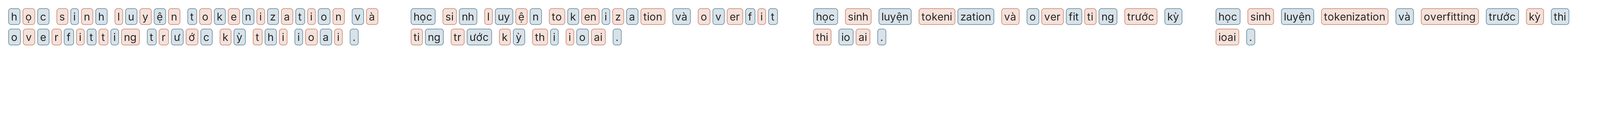

WordPiece, tokenizer của BERT, cũng học một từ vựng subword nhưng khác BPE ở hai chỗ. Khi học, nó không chọn cặp xuất hiện nhiều nhất mà chọn cặp có điểm $\frac{f(a,b)}{f(a)\,f(b)}$ cao nhất ($f$ là tần suất, theo mô tả của Hugging Face), tức ưu tiên hai mảnh hiếm khi đứng riêng. Nó chỉ lưu từ vựng cuối, không lưu luật gộp; khi mã hóa, nó lấy mảnh dài nhất có trong từ vựng khớp từ đầu từ, rồi lặp lại với phần còn lại; tiền tố `##` đánh dấu mảnh nối tiếp theo quy ước của BERT. Nếu đến một chỗ không mảnh nào khớp, cả từ thành `[UNK]`. Cùng một từ có thể bị hai tokenizer cắt khác nhau, nên với model pretrained, in token thật do tokenizer của model trả về thay vì đoán từ tên model.

**Hỏi nhanh.** Từ vựng WordPiece chỉ có `un`, `una`, `##able` và `[UNK]`. Mã hóa từ `unable` thì được gì?

- A. `un`, `##able`
- B. `una`, `##ble`
- C. `una`, `##b`, `##le`
- D. `[UNK]`

<details><summary>Đáp án</summary>

D. `[UNK]`

Mảnh dài nhất khớp với đầu từ là `una`, dài hơn `un`. Phần còn lại là `ble`, cần `##ble`, `##bl` hoặc `##b`, nhưng không mảnh nào có trong từ vựng, nên cả từ thành `[UNK]`. Cách cắt `un` cộng `##able` có tồn tại, nhưng thuật toán tham lam không quay lui để thử. `##ble`, `##b` và `##le` không có trong từ vựng, nên hai kết quả còn lại không thể xuất hiện.

</details>



## Từ chuỗi token đến TF-IDF

Baseline cổ điển không cần subword: ta đếm âm tiết hoặc cụm âm tiết xuất hiện trong nhận xét. Bag-of-words đặt mỗi mục từ thành một cột; mỗi câu thành một hàng. Nó giữ tần suất nhưng bỏ vị trí. Vì thế “An giúp Bình” và “Bình giúp An” có cùng vector unigram. Bigram (hai token liền nhau) khôi phục một phần thứ tự, nhưng vẫn không biểu diễn toàn bộ cấu trúc câu.

TF-IDF giảm trọng số của những mục xuất hiện ở quá nhiều câu. Với cấu hình mặc định làm trơn IDF của scikit-learn, nếu có $n$ câu train và mục $j$ xuất hiện trong $\operatorname{df}_j$ câu, ta dùng

$$\operatorname{idf}_j = \log\frac{1+n}{1+\operatorname{df}_j}+1.$$

Trước chuẩn hóa, đặc trưng là số lần xuất hiện nhân IDF. Sau đó, mặc định mỗi hàng được chuẩn hóa có độ dài L2 bằng 1 nếu khác vector 0. Từ lặp nhiều được nhấn mạnh trong câu, từ quá phổ biến được giảm tương đối. Không có “hiểu nghĩa” nào tự xuất hiện từ công thức này: hai từ đồng nghĩa khác chữ vẫn ở hai cột.

**Hỏi nhanh.** Sau TF-IDF có chuẩn hóa L2 mặc định, nhận xét “hay” và nhận xét “hay hay hay” cho ra hai vector thế nào?

- A. Vector thứ hai gấp ba lần vector thứ nhất
- B. Hai vector bằng nhau
- C. Vector thứ hai gấp $\sqrt 3$ lần vector thứ nhất
- D. Hai vector khác nhau, vì IDF tính theo số lần lặp trong câu

<details><summary>Đáp án</summary>

B. Hai vector bằng nhau

Cả hai chỉ có một ô khác 0, ở cột “hay”. Trước khi chuẩn hóa, ô ấy là $1\cdot\mathrm{idf}$ và $3\cdot\mathrm{idf}$. Chia cho độ dài thì cả hai đều thành 1 ở cột đó. Số lần lặp chỉ có tác dụng tương đối giữa các mục trong cùng một câu. IDF đếm số câu chứa mục, không đếm số lần lặp trong câu.

</details>



Với phân loại nhị phân, logistic regression cho điểm $z=\mathbf{w}^{\top}\mathbf{x}+b$, rồi xác suất $p=1/(1+e^{-z})$. Ở đây nhãn 1 là nhận xét tích cực và nhãn 0 là nhận xét tiêu cực. Thư viện học $\mathbf{w},b$ bằng loss phân loại và regularization. Ta đã học logistic regression ở chương 2; điểm mới là $\mathbf{x}$ được rút từ văn bản.

Một baseline cổ điển khác là Naive Bayes đa thức (multinomial). Nó giả định các token độc lập với nhau khi đã biết nhãn, nên xác suất của cả câu là tích xác suất từng token:

$$\log P(y\mid\mathbf{x}) = \log P(y) + \sum_j x_j \log P(j\mid y) + \text{const},\qquad P(j\mid y)=\frac{c_{jy}+\alpha}{\sum_k c_{ky}+\alpha\lvert V\rvert}.$$

Ở đây $x_j$ là số lần mục $j$ có trong câu, $c_{jy}$ là tổng số lần mục $j$ xuất hiện trong các câu train nhãn $y$, còn $\alpha$ (thường bằng 1, gọi là làm trơn Laplace) giữ cho mục chưa gặp ở một lớp không có xác suất 0. Học chỉ là đếm, nên Naive Bayes chạy rất nhanh và thường mạnh khi ít dữ liệu. Giả định độc lập sai với văn bản: “theo” gần như luôn đi cùng “dõi”, nên cùng một bằng chứng bị cộng hai lần và xác suất bị đẩy về gần 0 hoặc 1. Hiệu log-xác suất của hai lớp là tổng có trọng số của các $x_j$, nên Naive Bayes cũng là một bộ phân loại tuyến tính trên vector đếm.

## Dựng baseline trên dữ liệu nhỏ

Ta tự viết 12 câu train và 6 câu validation, không tải dữ liệu. Sáu câu đủ để soi từng lỗi nhưng quá ít để so hai model: mỗi câu đổi accuracy $1/6\approx0.167$. Validation cố ý chứa hai câu phủ định để tìm giới hạn của biểu diễn. Các câu cùng nhãn không được mặc định là độc lập nếu chúng là bản sao hoặc cùng một người viết.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

train_texts = [
    "bài học hay dễ hiểu", "nội dung rõ ràng bổ ích",
    "bài giảng tốt dễ theo dõi", "ví dụ hay hữu ích",
    "khóa học thú vị", "lời giải rõ ràng",
    "bài học khó hiểu nhàm chán", "nội dung kém rối",
    "bài giảng tệ khó theo dõi", "ví dụ sai vô ích",
    "khóa học nhàm chán", "lời giải rối sai",
]
train_labels = np.array([1] * 6 + [0] * 6)
valid_texts = [
    "bài học hay", "lời giải sai", "bài giảng không hay",
    "ví dụ rõ ràng", "nội dung rối", "khóa học không tệ",
]
valid_labels = np.array([1, 0, 0, 1, 0, 1])

baseline = Pipeline([
    ("tfidf", TfidfVectorizer(preprocessor=normalize_text, ngram_range=(1, 2))),
    ("classifier", LogisticRegression(C=4.0, random_state=0, max_iter=1000)),
])
baseline.fit(train_texts, train_labels)
valid_pred = baseline.predict(valid_texts)
print("shape train:", baseline["tfidf"].transform(train_texts).shape)
print("accuracy:", f"{accuracy_score(valid_labels, valid_pred):.3f}")
print("macro-F1:", f"{f1_score(valid_labels, valid_pred, average='macro'):.3f}")
print(confusion_matrix(valid_labels, valid_pred, labels=[0, 1]))

shape train: (12, 69)
accuracy: 0.667
macro-F1: 0.667
[[2 1]
 [1 2]]


Shape `(12, 69)` nghĩa là 12 câu train và 69 mục: 31 âm tiết cùng 38 bigram đã gặp trong train. Confusion matrix có hàng là nhãn thật, cột là nhãn đoán, theo thứ tự `[0, 1]`. Hai ô đường chéo là số câu đúng, hai ô còn lại chỉ hướng nhầm. Accuracy đếm tổng số đúng chia 6; macro-F1 lấy trung bình F1 của hai lớp để mỗi lớp có vai trò ngang nhau. Trên dữ liệu lệch lớp, accuracy cao vẫn có thể che một lớp bị bỏ qua.



Trong `Pipeline`, TF-IDF được fit trên train, rồi dùng cùng vocabulary và IDF khi gọi `predict(valid_texts)`. Ta không gọi `fit_transform` riêng trên validation: thứ tự cột có thể đổi và thống kê của validation sẽ lọt vào thí nghiệm. Có cuộc thi cho phép fit vectorizer trên cả văn bản test không nhãn; khi luật cho phép, cách làm ấy phải áp dụng như nhau cho mọi thí nghiệm để các điểm còn so được với nhau.

**Hỏi nhanh.** Ta muốn chạy 5-fold cross-validation cho baseline trên cả 18 câu có nhãn. Làm cách nào thì điểm mới tin được?

- A. Fit `TfidfVectorizer` trên cả 18 câu, rồi CV logistic trên ma trận
- B. Fit `TfidfVectorizer` riêng trên phần validation của từng fold
- C. Giữ vectorizer đã fit trên 12 câu train, chỉ CV phần logistic
- D. Đưa cả `Pipeline` cùng văn bản thô vào `cross_val_score`

<details><summary>Đáp án</summary>

D. Đưa cả `Pipeline` cùng văn bản thô vào `cross_val_score`

`cross_val_score` fit lại toàn bộ `Pipeline` trên phần train của mỗi fold, nên vocabulary và IDF chỉ đến từ phần đó. Fit trên cả 18 câu thì fold validation góp cả cột lẫn IDF. Chẳng hạn khi hai câu có “không” cùng rơi vào fold validation, cột “không” vẫn tồn tại, và IDF của nó lấy từ chính những câu đang chấm. Fit riêng trên validation làm lệch thứ tự cột. Vectorizer fit trên 12 câu train đã thấy những câu sẽ nằm trong các fold validation, nên vẫn rò.

</details>

## Đọc câu sai trước khi tăng độ phức tạp

Ta cần xem từng nhận xét, thay vì chỉ nhìn một điểm tổng. Cột xác suất dưới đây là xác suất model gán cho nhãn 1, không phải xác suất rằng model “hiểu câu”.

In [ ]:
positive_index = list(baseline["classifier"].classes_).index(1)
positive_prob = baseline.predict_proba(valid_texts)[:, positive_index]
for text, true, pred, prob in zip(valid_texts, valid_labels, valid_pred, positive_prob):
    print(f"thật={true} đoán={pred} p1={prob:.3f} | {text}")
print("'không' có trong vocabulary:", "không" in baseline["tfidf"].vocabulary_)

thật=1 đoán=1 p1=0.651 | bài học hay
thật=0 đoán=0 p1=0.407 | lời giải sai
thật=0 đoán=1 p1=0.597 | bài giảng không hay
thật=1 đoán=1 p1=0.700 | ví dụ rõ ràng
thật=0 đoán=0 p1=0.370 | nội dung rối
thật=1 đoán=0 p1=0.448 | khóa học không tệ
'không' có trong vocabulary: False


Hai câu chứa “không” cần được xem xét. Từ này không có trên train nên bị bỏ trong biểu diễn; `không hay` không thể được nhận diện bằng bigram đã học. Model còn nhìn thấy “hay” hoặc “tệ”, rồi suy ra hướng ngược với nghĩa cả câu. Baseline đã có bigram, nhưng một bigram chỉ thành cột khi đã xuất hiện trong train.



Liệu một bộ phân loại khác có cứu được? Giữ nguyên dữ liệu, thay logistic regression bằng Naive Bayes trên vector đếm:

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

naive_bayes = Pipeline([
    ("count", CountVectorizer(preprocessor=normalize_text, ngram_range=(1, 2))),
    ("classifier", MultinomialNB(alpha=1.0)),
])
naive_bayes.fit(train_texts, train_labels)
print("NB đoán:", naive_bayes.predict(valid_texts))
print("thật:   ", valid_labels)

NB đoán: [1 0 1 1 0 0]
thật:    [1 0 0 1 0 1]


Naive Bayes sai đúng hai câu có “không”: hai bộ phân loại khác nhau, một đọc TF-IDF, một đọc vector đếm, nhưng cùng một vocabulary đã mất từ phủ định, nên nhầm như nhau. Cách cải thiện bắt đầu từ biểu diễn và dữ liệu: thêm câu phủ định đủ đa dạng vào train, đánh giá trên người viết hoặc chủ đề chưa thấy, rồi mới cân nhắc model ngữ cảnh ở bài 6.3.



**Hỏi nhanh.** Cả logistic regression lẫn Naive Bayes đều đoán ngược hai câu có chữ “không”. Bước tiếp theo nào nhắm đúng nguyên nhân?

- A. Thử thêm một classifier mạnh hơn, như gradient boosting
- B. Hạ threshold để các câu phủ định rơi về lớp 0
- C. In ra các feature còn lại của câu sau `transform`
- D. Tăng `C` để model chú ý hơn tới các từ hiếm

<details><summary>Đáp án</summary>

C. In ra các feature còn lại của câu sau `transform`

Hai model khác nhau cùng sai ở cùng hai câu, nên lỗi nhiều khả năng nằm ở phần biểu diễn chung. “Không” chưa có cột, nên mọi classifier phía sau đều không thấy nó. Xem các feature còn lại, chẳng hạn bằng `baseline["tfidf"].inverse_transform(...)`, sẽ xác nhận điều đó trước khi tốn công đổi model. Hạ threshold không đúng hướng: “khóa học không tệ” cần lên lớp 1, còn “bài giảng không hay” cần xuống lớp 0. `C` chỉ đổi mức regularization, không tạo cột cho từ chưa gặp.

</details>

## Ví dụ tính tay

Giả sử train có ba câu: “hay dễ”, “hay rõ”, “khó”. Mục “hay” xuất hiện trong hai câu nên IDF bằng $\log(4/3)+1\approx1.288$; “dễ” xuất hiện trong một câu nên bằng $\log(4/2)+1\approx1.693$. Vector chưa chuẩn hóa của “hay dễ” trên hai cột này là $(1.288,1.693)$. Độ dài của nó xấp xỉ 2.127, nên sau chuẩn hóa là $(0.605,0.796)$. Tích vô hướng với trọng số giả định $(1,-1)$ và bias 0 cho $z\approx-0.191$, tức $p\approx0.452$. Trọng số $(1,-1)$ được chọn để luyện tính, không lấy từ baseline.

In [ ]:
raw = np.array([np.log(4 / 3) + 1, np.log(4 / 2) + 1])
unit = raw / np.linalg.norm(raw)
z_hand = unit @ np.array([1.0, -1.0])
print("idf:", raw.round(3))
print("tfidf:", unit.round(3))
print("p:", round(1 / (1 + np.exp(-z_hand)), 3))

idf: [1.288 1.693]
tfidf: [0.605 0.796]
p: 0.452


Code cho đúng ba số đã tính tay. Nếu “hay” có mặt ở cả ba câu, IDF của nó là $\log(4/4)+1=1$: mục phổ biến chỉ bị giảm tương đối, không bị xóa khỏi biểu diễn.

**Hỏi nhanh.** Giữ IDF như trên, trọng số giả định là $(1, -1)$ và bias bằng 0. Câu “hay hay dễ” cho $p$ xấp xỉ bao nhiêu?

- A. 0.452, giống câu “hay dễ”
- B. 0.707
- C. 0.571
- D. 0.500, vì chuẩn hóa xóa hiệu ứng lặp

<details><summary>Đáp án</summary>

C. 0.571

Vector chưa chuẩn hóa là $(2\cdot 1.288,\ 1.693) = (2.576,\ 1.693)$, độ dài khoảng 3.083. Sau chuẩn hóa còn $(0.836,\ 0.549)$. Khi đó $z \approx 0.286$ và $p = \sigma(0.286) \approx 0.571$. Lặp “hay” làm vector nghiêng về cột “hay”, nên $p$ khác 0.452. Chuẩn hóa chỉ xóa hiệu ứng lặp khi mọi mục trong câu lặp cùng số lần. 0.707 là kết quả khi quên chuẩn hóa, lúc đó $z = 2.576 - 1.693 = 0.883$.

</details>

## Bẫy cài đặt

`TfidfVectorizer` mặc định viết thường và chỉ giữ token có từ hai ký tự chữ hoặc số trở lên (`token_pattern` là `(?u)\b\w\w+\b`). Nếu ký hiệu như “C”, “R”, “x” là quan trọng, phải đổi `token_pattern` hoặc dùng tokenizer riêng. Với văn bản có lỗi gõ, char n-gram thường là baseline đáng thử; dùng nó không đồng nghĩa đã sửa chính tả. Không xóa dấu, emoji, chữ hoa một cách máy móc trước khi biết chúng có mang nhãn hay không.

**Hỏi nhanh.** Ta phân loại câu hỏi theo ngôn ngữ lập trình. Ba câu train là “bài C++ khó”, “bài R dễ” và “bài Go hay”. `TfidfVectorizer()` mặc định học được vocabulary nào?

- A. `bài, c++, dễ, go, hay, khó, r`
- B. `bài, c, dễ, go, hay, khó, r`
- C. `bài, dễ, go, hay, khó`
- D. `bài, dễ, hay, khó`

<details><summary>Đáp án</summary>

C. `bài, dễ, go, hay, khó`

Vectorizer viết thường, rồi chỉ giữ những chuỗi chữ hoặc số dài từ hai ký tự trở lên. `+` không phải chữ, nên `c++` chỉ còn `c`. `c` và `r` dài một ký tự nên bị bỏ, còn `go` có hai ký tự nên ở lại. Hai trong ba tên ngôn ngữ mất hẳn tín hiệu. Sửa bằng `token_pattern=r"(?u)\b\w+\b"`, hoặc dùng tokenizer riêng nếu cần giữ nguyên `c++`.

</details>



Bản sao và bản gần trùng (chép lại, chỉ khác dấu câu hay chữ hoa) nằm ở cả train và validation làm điểm cao giả tạo. Chuẩn hóa văn bản rồi loại trùng trước khi chia; nếu dữ liệu có cấu trúc người viết, tài liệu hay thời gian thì chia theo cấu trúc ấy. Lưu class mapping cùng vectorizer và model, vì nhãn số 0/1 chỉ có nghĩa khi đi kèm bảng ánh xạ.

Quay lại nhận xét lớp học: baseline giúp xếp một danh sách để đọc, nhưng không nên tự quyết định mọi câu là khen hay chê. Những trường hợp phủ định, câu mỉa mai, nhận xét vừa khen vừa chê cần được kiểm riêng. Một baseline nhỏ, có lỗi được giải thích, là nền tốt để biết model tiếp theo cải thiện điều gì.

## Khi đi thi

- **Dựng TF-IDF cùng logistic regression trước tiên.** Chạy vài giây trên CPU, cho một điểm mốc và một file nộp hợp lệ; model pretrained chỉ đáng tiền GPU khi vượt rõ mốc này.
- **Chia validation giống cách tạo test.** Test là người viết, tài liệu hay giai đoạn mới thì chia theo nhóm hoặc thời gian; loại bản trùng trước khi chia.
- **Đổi một thành phần mỗi lần.** Unigram so với unigram cùng bigram, word so với `char_wb`, rồi mới chỉnh `C`, trên cùng split và đúng metric đề chấm.
- **Đọc câu sai và feature trước khi đổi model.** In token còn lại sau `transform`, đếm số câu thành vector 0, kiểm token bị bỏ: một ký tự, ký hiệu, từ phủ định.
- **Dùng đúng tokenizer của model pretrained.** Đếm độ dài bằng chính tokenizer đó trước khi chọn `max_length`; đọc luật về model ngoài và Internet, chuẩn bị file sẵn khi phải chạy offline.
- **Kiểm file nộp.** Giữ đúng thứ tự ID của test, đổi nhãn số về tên lớp bằng bảng đã lưu, lấy cột `predict_proba` theo `classes_`.

## Tóm tắt

- Token là đơn vị của tokenizer; tiếng Việt có khoảng trắng giữa âm tiết nên phải kiểm ranh giới từ.
- BPE học luật gộp theo tần suất có trọng số và áp lại đúng thứ tự; WordPiece mã hóa tham lam bằng mảnh dài nhất, không khớp thì `[UNK]`.
- TF-IDF là biểu diễn từ vựng; logistic regression và Naive Bayes là bộ phân loại tuyến tính đọc nó; cả pipeline fit trên train.
- Điểm tổng đi cùng câu sai và confusion matrix; hai model cùng sai một câu thì xem biểu diễn và dữ liệu trước khi đổi model. Phủ định, từ lạ và bản trùng là những phép thử cần có.

## Kiểm tra cuối bài

**Câu 1.** Bình luận sản phẩm có nhiều tên hãng mới và lỗi gõ như “đẹppp”. Tokenizer theo từ đã có 300 nghìn mục mà test vẫn đầy từ lạ. Chuyển sang subword như BPE hay WordPiece thì được lợi chính ở đâu?

- A. Chạy nhanh hơn, vì chuỗi subword luôn ngắn hơn chuỗi từ
- B. Cài đặt đơn giản hơn, vì không phải học từ vựng trên train
- C. Không có lợi với tiếng Việt, vì subword chỉ học được trên tiếng Anh
- D. Từ lạ được ghép từ mảnh quen, từ vựng nhỏ, từ cùng gốc dùng chung mảnh

<details><summary>Đáp án</summary>

D. Từ lạ được ghép từ mảnh quen, từ vựng nhỏ, từ cùng gốc dùng chung mảnh

Subword giữ những mảnh thường gặp thành token, và chia từ hiếm thành nhiều mảnh. Vì vậy “đẹppp” vẫn thành vài mảnh đã biết, thay vì một `[UNK]`. Vài chục nghìn mảnh thay được cho hàng trăm nghìn từ. Các từ cùng gốc như `play` và `playing` dùng chung mảnh `play`. Chuỗi subword thường dài hơn chuỗi từ, không ngắn hơn. BPE và WordPiece đều phải học từ vựng trên corpus. Thuật toán không phụ thuộc ngôn ngữ: học trên corpus tiếng Việt thì cho ra mảnh tiếng Việt.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 235](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=85)

</details>

**Câu 2.** Đề giới hạn mỗi bình luận 128 token, đếm theo tokenizer của model cho sẵn. Đếm bằng `split()` thì bình luận dài nhất có 110 âm tiết. Bình luận ấy có vừa giới hạn không?

- A. Chắc chắn vừa, vì mỗi âm tiết là đúng một token
- B. Chắc chắn vừa, vì tokenizer gộp âm tiết nên token ít hơn
- C. Chưa biết, phải đếm bằng chính tokenizer của model
- D. Chắc chắn tràn, vì mỗi ký tự là một token

<details><summary>Đáp án</summary>

C. Chưa biết, phải đếm bằng chính tokenizer của model

Tokenizer cắt văn bản thành từ hoặc subword theo từ vựng của nó, rồi thêm các token đặc biệt như `[CLS]` và `[SEP]`. Tokenizer đa ngôn ngữ có thể chia một âm tiết tiếng Việt có dấu thành nhiều mảnh, nên 110 âm tiết có thể vượt 128 token. Tokenizer tách theo từ thì lại có thể cho ít token hơn. Tokenizer mức ký tự là một loại riêng, không phải mặc định. Phần vượt giới hạn thường bị cắt ở cuối, có khi đúng chỗ chứa ý chính.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 227](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=82)

</details>

**Câu 3.** Corpus là list từ `["bun"]*5 + ["sun", "sing", "king", "ring"]`. Một bạn đếm các cặp ký tự kề nhau trong vòng `for word in set(corpus)`, và phá hòa theo thứ tự từ điển. Bước gộp BPE đầu tiên đúng ra là gì, và code này gộp gì?

- A. Đúng ra là `i,n` với 3 lần, code gộp `u,n` với 2 lần
- B. Đúng ra là `u,n` với 6 lần, code gộp `i,n` với 3 lần
- C. Cả hai đều gộp `u,n`, chỉ khác số đếm
- D. Cả hai đều gộp `i,n`, chỉ khác số đếm

<details><summary>Đáp án</summary>

B. Đúng ra là `u,n` với 6 lần, code gộp `i,n` với 3 lần

Đếm có trọng số thì `u,n` có trong `bun` 5 lần và `sun` 1 lần, tổng là 6. `i,n` và `n,g` mỗi cặp 3 lần. `set` khử các bản lặp, nên mỗi loại từ chỉ góp 1. `u,n` còn 2, còn `i,n` và `n,g` vẫn là 3, hòa nhau, và phá hòa chọn `i,n`. Đếm theo loại từ là đổi luôn bài toán: từ phổ biến nhất mất ưu thế. Cách đúng là dùng `Counter(corpus)`, rồi nhân tần suất vào từng cặp như code trong bài.
Phỏng theo: [USA-NA-AIO 2026 · Vòng 1 · Part 5.1–5.2](https://www.usaaio.org/attachments/past-problems/2026/usaaio-2026-round-1-problems.pdf#page=11)

</details>

**Câu 4.** Đây là hàm mã hóa câu cho một model sinh văn bản.
```py
tokens = [BOS] + [vocab.get(w, UNK) for w in text.split()] + [EOS]
if len(tokens) < max_len:
    tokens += [PAD] * (max_len - len(tokens))
else:
    tokens = tokens[:max_len]
```
Với `max_len = 8` và một câu 9 từ, lỗi nghiêm trọng nhất là gì?

- A. `PAD` mang ID 0, nên loss tính cả các vị trí đệm
- B. Tokenizer theo từ làm vocabulary quá lớn, phải đổi sang BPE
- C. `BOS` chiếm một chỗ, nên câu ngắn bị pad thiếu
- D. Chuỗi bị cắt chỉ còn `BOS` và 7 từ, mất hẳn `EOS`

<details><summary>Đáp án</summary>

D. Chuỗi bị cắt chỉ còn `BOS` và 7 từ, mất hẳn `EOS`

Chuỗi đủ có $1 + 9 + 1 = 11$ token. `tokens[:8]` giữ `BOS` và 7 từ đầu, bỏ 2 từ cuối cùng với `EOS`. Với mọi câu dài, model không thấy dấu kết thúc, nên học sai ranh giới chuỗi, và khi sinh có thể không biết dừng. Cách sửa là cắt phần nội dung còn `max_len - 2` token, rồi mới thêm `BOS` và `EOS`. Việc `PAD` không được tính vào loss là do attention mask và nhãn `-100` lo, ở bước tạo label, không phải lỗi của hàm này. Tokenizer theo từ là một lựa chọn thiết kế, không làm hỏng chuỗi. Câu ngắn vẫn được pad đủ `max_len`.
Phỏng theo: [NOAI 2026 Singapore · Chung kết · Câu 19](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Final-Assessment-Section-1-MCQs-Google-Forms.pdf#page=30)

</details>

**Câu 5.** Một đội lọc tin nhắn rác bằng Naive Bayes trên bag-of-words. Hai từ “khuyến” và “mãi” gần như luôn đi cùng nhau, nhưng mô hình tính chúng như hai bằng chứng độc lập. Hệ quả là gì?

- A. Phép tính gọn, xác suất ra quá tự tin, nhưng nhãn thường vẫn đúng
- B. Không có hệ quả gì, vì giả định độc lập luôn đúng khi đã tách từ cẩn thận
- C. Không có hệ quả gì, vì Naive Bayes tự học tương tác giữa các từ
- D. Mô hình không cần train, chỉ cần danh sách từ rác cho sẵn

<details><summary>Đáp án</summary>

A. Phép tính gọn, xác suất ra quá tự tin, nhưng nhãn thường vẫn đúng

Giả định độc lập biến xác suất của cả câu thành tích xác suất của từng token, nên việc học chỉ là đếm và chạy rất nhanh. Cặp “khuyến mãi” được cộng log-xác suất hai lần, nên xác suất bị đẩy về gần 0 hoặc gần 1. Nhưng phân loại chỉ cần biết lớp nào có điểm cao hơn, và thứ tự ấy thường vẫn đúng. Từ hay đi cùng nhau là đặc điểm của ngôn ngữ, tách từ không làm chúng độc lập. Naive Bayes không học tương tác. Thêm bigram chỉ thêm cột, và các cột vẫn bị coi là độc lập. Nó học $P(j\mid y)$ bằng cách đếm trên dữ liệu có nhãn.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 169](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=63)

</details>

**Câu 6.** Vectorizer fit trên train có ba cột `[dở, hay, tệ]`. Một vectorizer khác fit riêng trên validation cho `[dở, hay, ổn]`. Shape đều đúng ba cột. Vì sao không đưa ma trận validation này vào classifier cũ được?

- A. Vì TF-IDF fit trên validation không chứa được giá trị 0
- B. Vì cột thứ ba đã đổi nghĩa, dù shape vẫn bằng nhau
- C. Vì classifier nhị phân chỉ nhận đúng một cột đặc trưng
- D. Vì số câu validation phải bằng số câu train

<details><summary>Đáp án</summary>

B. Vì cột thứ ba đã đổi nghĩa, dù shape vẫn bằng nhau

Model học hệ số theo vị trí cột. Hệ số âm học cho “tệ” ở cột thứ ba giờ nhân với giá trị TF-IDF của “ổn”, nên câu khen bị kéo về lớp chê. IDF cũng tính trên validation chứ không phải trên train. Ma trận TF-IDF vẫn đầy số 0. Classifier nhị phân nhận bao nhiêu cột cũng được, và số câu của hai tập không cần bằng nhau. Hãy dùng `transform` của vectorizer đã fit trên train, hoặc gói hai bước vào `Pipeline`.

</details>

**Câu 7.** Validation có nhiều lỗi gõ như “hayyy”, “haay”, không có trong vocabulary từ của train. Nên thử đổi biểu diễn theo hướng nào trước?

- A. Dùng char n-gram, ví dụ `analyzer="char_wb"`
- B. Tăng `ngram_range` theo từ lên `(1, 3)` để có thêm cột
- C. Giảm `C` để model bớt tin vào từ chưa gặp
- D. Bỏ dấu toàn bộ văn bản để gộp các biến thể lại

<details><summary>Đáp án</summary>

A. Dùng char n-gram, ví dụ `analyzer="char_wb"`

Char n-gram chia từ thành các mảnh ký tự, nên “hayyy” và “hay” có chung những mảnh như ` ha` và `hay`. Với `char_wb` từ 2 tới 4 ký tự fit trên 12 câu train của bài, “hayyy” bật 7 cột đã học, còn vectorizer theo từ cho ra vector 0. N-gram theo từ dài hơn vẫn dựa trên từ nguyên vẹn, nên từ gõ sai vẫn bị bỏ. Đổi `C` không tạo cột cho từ lạ. Bỏ dấu không cứu được “hayyy”, lại làm mất khác biệt giữa “ma” và “má”.

</details>

**Câu 8.** Lớp cần tìm là nhận xét chê, nhãn 0, chiếm 20% validation. Đội báo `f1_score(y_true, y_pred)` bằng 0.93. Con số này đo gì?

- A. F1 của lớp chê, đúng thứ cần báo
- B. F1 của lớp khen, vốn là lớp dương mặc định
- C. Trung bình F1 của hai lớp, như macro-F1
- D. Accuracy, vì hai nhãn đều là số nguyên

<details><summary>Đáp án</summary>

B. F1 của lớp khen, vốn là lớp dương mặc định

`f1_score` nhị phân mặc định `pos_label=1`, nên 0.93 là F1 của lớp khen, chiếm 80% và là lớp dễ. Muốn đo khả năng bắt nhận xét chê, hãy gọi `f1_score(y_true, y_pred, pos_label=0)`, hoặc dùng `average=None` để xem từng lớp. Nếu đề chấm macro-F1 thì dùng `average="macro"`. Hàm này không tự lấy trung bình hai lớp, và cũng không tính accuracy.

</details>

**Câu 9.** Mỗi học sinh viết khoảng 20 nhận xét với văn phong riêng. Split ngẫu nhiên cho macro-F1 0.91, còn `GroupKFold` theo học sinh cho 0.74. Test là nhận xét của một khóa học sinh mới. Nên báo và chọn model theo số nào?

- A. 0.74, vì test là những người viết chưa từng thấy
- B. 0.825, trung bình hai cách để bớt lệch
- C. 0.91, vì split ngẫu nhiên có nhiều dữ liệu train hơn
- D. 0.91, rồi trừ đi một khoảng an toàn cố định

<details><summary>Đáp án</summary>

A. 0.74, vì test là những người viết chưa từng thấy

Split ngẫu nhiên đặt câu của cùng một người ở cả hai phía. Model nhận ra văn phong, cụm từ quen, thậm chí câu chép lại, nên điểm phản ánh khả năng nhớ người viết. Test gồm người mới, giống với `GroupKFold` theo học sinh. Với cùng số fold, hai cách chia dùng lượng train như nhau, nên chênh lệch không đến từ lượng dữ liệu. Lấy trung bình hai con số hay trừ một khoảng cố định đều không đo đúng tình huống của test.

</details>

**Câu 10.** Câu validation “quá đỉnh luôn” có mọi từ nằm ngoài vocabulary TF-IDF. Logistic regression đã học có bias $b = -0.2$. Model trả về xác suất lớp 1 bằng bao nhiêu?

- A. 0.500, vì không có thông tin nên chia đều
- B. 0.000, vì vector rỗng không thuộc lớp nào
- C. Khoảng 0.450
- D. Không có, vì code báo lỗi khi chuẩn hóa vector 0

<details><summary>Đáp án</summary>

C. Khoảng 0.450

Không mục nào khớp, nên vector TF-IDF toàn số 0, và scikit-learn để nguyên vector 0 khi chuẩn hóa L2. Khi đó $z = \mathbf{w}^\top\mathbf{0} + b = -0.2$, và $p = \sigma(-0.2) \approx 0.450$. Model chỉ còn bias, tức đoán theo xu hướng chung của train. Không có lỗi, cũng không chia đều. Hãy đếm tỉ lệ câu validation và test thành vector 0. Tỉ lệ ấy cao nghĩa là biểu diễn đang bỏ quá nhiều chữ.

</details>

## Đọc thêm

- Jurafsky, Martin — [Speech and Language Processing, Words and Tokens](https://web.stanford.edu/~jurafsky/slp3/2.pdf) và [Text Classification](https://web.stanford.edu/~jurafsky/slp3/4.pdf). Đọc để nối token với đặc trưng và nhiệm vụ phân loại.
- Sennrich và cộng sự — [Neural Machine Translation of Rare Words with Subword Units](https://aclanthology.org/P16-1162/). Nguồn gốc ứng dụng BPE cho từ hiếm trong NLP.
- Hugging Face — [BPE](https://huggingface.co/learn/llm-course/en/chapter6/5), [WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6). Xem sự khác nhau giữa học vocabulary và mã hóa câu mới.
- scikit-learn — [Text feature extraction](https://scikit-learn.org/stable/modules/feature_extraction.html#text-feature-extraction). Kiểm chính xác IDF, chuẩn hóa và `token_pattern` của thư viện.
- VinAI — [PhoBERT](https://github.com/VinAIResearch/PhoBERT). Đọc yêu cầu tách từ tiếng Việt trước khi dùng tokenizer này.